In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
# détermination des rôles des colonnes
roles = {
    "TARGETS": "Quality indicator",
    "TEST_CONDITION": "Test condition",
    "CHEMISTRY": "Molecular concentration"
}

for variable, role in roles.items():
    globals()[variable] = correspondance_between_names_units.loc[
        correspondance_between_names_units["Role"] == role, "Feature"
    ].tolist()

ID_COL = "Weld ID"

PROCESS_NUM = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "float64")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

PROCESS_CAT = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "str")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

In [4]:
# fonction d'actualisation des listes de variables
def update_liste(LIST, dataframe = df) : 
    return [f for f in LIST if f in df.columns]

##  Introduction : prise de connaissance des données

Commençons déjà par prendre connaissance avec les données, qui est une étape essentielle dans des projets data.

In [5]:
# avant de commencer, assurons nous que les lignes entières sont uniques (pas de doublons)
print("Avant suppression des doublons : ", df.shape)
df = df.drop_duplicates()
print("Après suppression des doublons : ", df.shape)
print("Nombre de targets : ", len(TARGETS))
df

Avant suppression des doublons :  (1652, 44)
Après suppression des doublons :  (1651, 44)
Nombre de targets :  7


,Carbon concentration,Silicon concentration,Manganese concentration,Sulphur concentration,Phosphorus concentration,Nickel concentration,Chromium concentration,Molybdenum concentration,Vanadium concentration,Copper concentration,...,Charpy temperature,Charpy impact toughness,Hardness,50 % FATT,Primary ferrite in microstructure,Ferrite with second phase,Acicular ferrite,Martensite,Ferrite with carbide aggreagate,Weld ID
0,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
1,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
2,0.037,0.30,0.65,0.008,0.012,0.00,NaN,NaN,NaN,NaN,...,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
3,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990
4,0.037,0.31,1.03,0.007,0.014,0.00,NaN,NaN,NaN,NaN,...,-48.0,100.0,NaN,NaN,32.0,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1647,0.100,0.35,0.90,0.008,0.016,0.60,8.6,0.98,0.18,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1648,0.088,0.36,0.88,0.008,0.017,0.57,8.4,0.94,0.19,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1649,0.090,0.34,0.89,0.008,0.016,0.17,8.2,0.94,0.02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham
1650,0.092,0.35,0.90,0.008,0.016,0.54,8.4,0.97,0.17,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Birmingham


En observant notre base de données, on peut connaître les informations suivantes : 
- 44 features différentes, dont 7 features sont les candidats en tant que variables cibles (ce sont des indicateurs de qualité) ; 
- 1651 lignes de données retenues, soit 99% (1651/1652) consérvées après suppression des doublons ; 
- les features `Weld ID` est la seule feature permettant de différencier/séparer les lignes de données. On compte 148 types de soudures différentes.

Ici, une `Weld ID` peut avoir plusieurs lignes, car ce sont les différentes tests effectués sur une soudure. Il indique l'auteur effectuant le test, le sujet d'étude sur la soudure et l'année de publication des résultats (par exemple : **Evans-Ni/CMn-1990** avec Evans l'auteur, l'étude est sur la réaction du Nickel et les résultats sont publiés en 1990). 

Naturellement, on déduit que l'état des données sera dépendante du `Weld ID` car ils ont été tous extraites des expériences et chacun des auteurs sont libres de ne partager des données ou non.

In [6]:
df["Weld ID"].value_counts()

Weld ID
Evans-AlTi-1994            114
Evans-StressRelief-1991    110
SvenGret-1990               96
Pat-1981                    79
EvansLetter                 78
                          ... 
EvansLetterC+1Cuch1          1
EvansLetterC+1Cuch2          1
EvansLetterC+1.5Cu           1
EvansLetterC+1.5Cuch1        1
EvansLetterC+1.5Cuch2        1
Name: count, Length: 148, dtype: int64

## 1. Etudes des valeurs manquantes

Pour que ça soit plus claire, nous allons regarder la répartition de valeurs manquantes en fonction des lignes, triés par `Weld ID`, pour chaque feature. Par ailleurs, nous mettrons une couleur vif pour les features à plus de 80% d'instances manquantes.

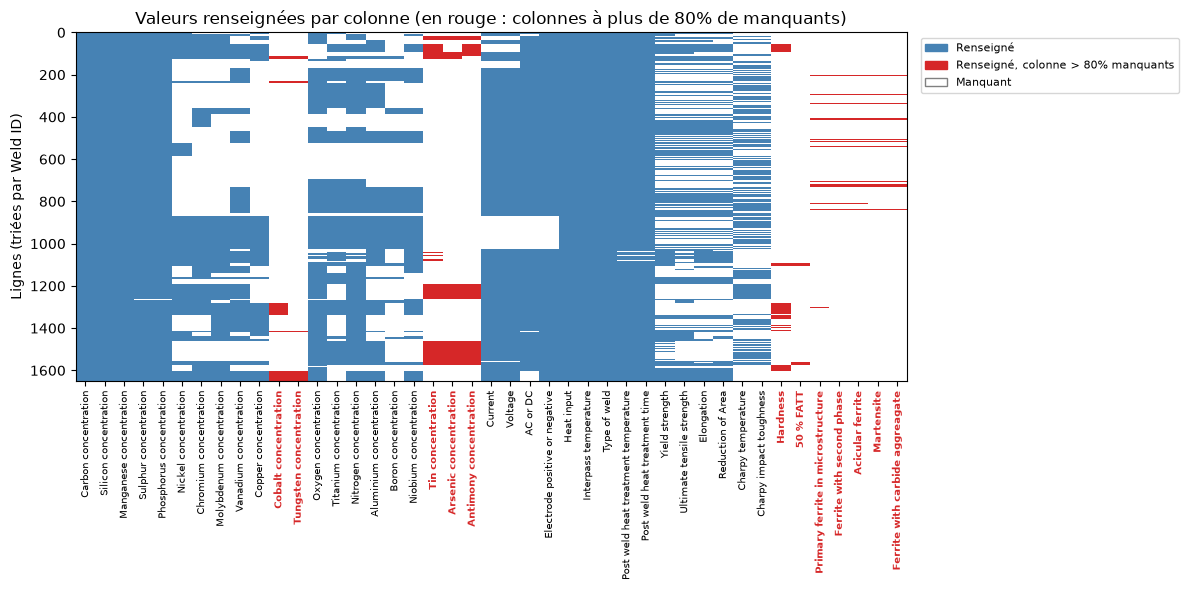

Le nombre de features à plus de 80% de données manquantes est :  12

 Informations sur ces features :


,Feature,Unit,Role,Types de variables
10,Cobalt concentration,(weight%),Molecular concentration,float64
11,Tungsten concentration,(weight%),Molecular concentration,float64
18,Tin concentration,(weight%),Molecular concentration,float64
19,Arsenic concentration,(weight%),Molecular concentration,float64
20,Antimony concentration,(weight%),Molecular concentration,float64
36,Hardness,kg/mm2,Quality indicator,float64
37,50 % FATT,NaN,Quality indicator,float64
38,Primary ferrite in microstructure,%,Microstructure,float64
39,Ferrite with second phase,%,Microstructure,float64
40,Acicular ferrite,%,Microstructure,float64


In [7]:
seuil = 0.80
df_sorted = df.sort_values("Weld ID")
X = df_sorted.drop(columns="Weld ID")
na = X.isna()
taux_na = na.mean()
tres_manquantes = taux_na > seuil

# 0 = manquant, 1 = présent, 2 = présent dans une colonne > 80 % de manquants
code = (~na).astype(int).values
code[:, tres_manquantes.values] *= 2
cmap = ListedColormap(["white", "steelblue", "tab:red"])

plt.figure(figsize=(12, 6))
plt.imshow(code, aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=2)
plt.xticks(range(X.shape[1]), X.columns, rotation=90, fontsize=7)
for lbl, flag in zip(plt.gca().get_xticklabels(), tres_manquantes):
    if flag:
        lbl.set_color("tab:red"); lbl.set_fontweight("bold")
plt.ylabel("Lignes (triées par Weld ID)")
plt.title(f"Valeurs renseignées par colonne (en rouge : colonnes à plus de {seuil:.0%} de manquants)")
plt.legend(handles=[Patch(color="steelblue", label="Renseigné"),
                    Patch(color="tab:red", label=f"Renseigné, colonne > {seuil:.0%} manquants"),
                    Patch(facecolor="white", edgecolor="gray", label="Manquant")],
           loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

print("Le nombre de features à plus de 80% de données manquantes est : ", tres_manquantes.sum())

print("\n Informations sur ces features :")
correspondance_between_names_units[correspondance_between_names_units["Feature"].isin(tres_manquantes[tres_manquantes].index)]

### 1.1) Suppression des features à plus de 80% de valeurs manquantes

Par la précédente analyse, nous avons au total 12 features à plus de 80% de données manquantes. On supprimera : 
- les features de type *microstructure*, car ce sont des résultats du procédé : on ne les connaît pas avant de souder, donc elles ne peuvent pas servir à prédire la qualité ;
- les features de type *qualité de soudure*, car les données sont trop rares ;
- les features de type *concentration moléculaire*, car les données sont trop peu pour avoir une imputation correcte.

In [8]:
df = df.drop(tres_manquantes[tres_manquantes].index, axis=1, inplace=False)

### 1.2) Etude des autres features



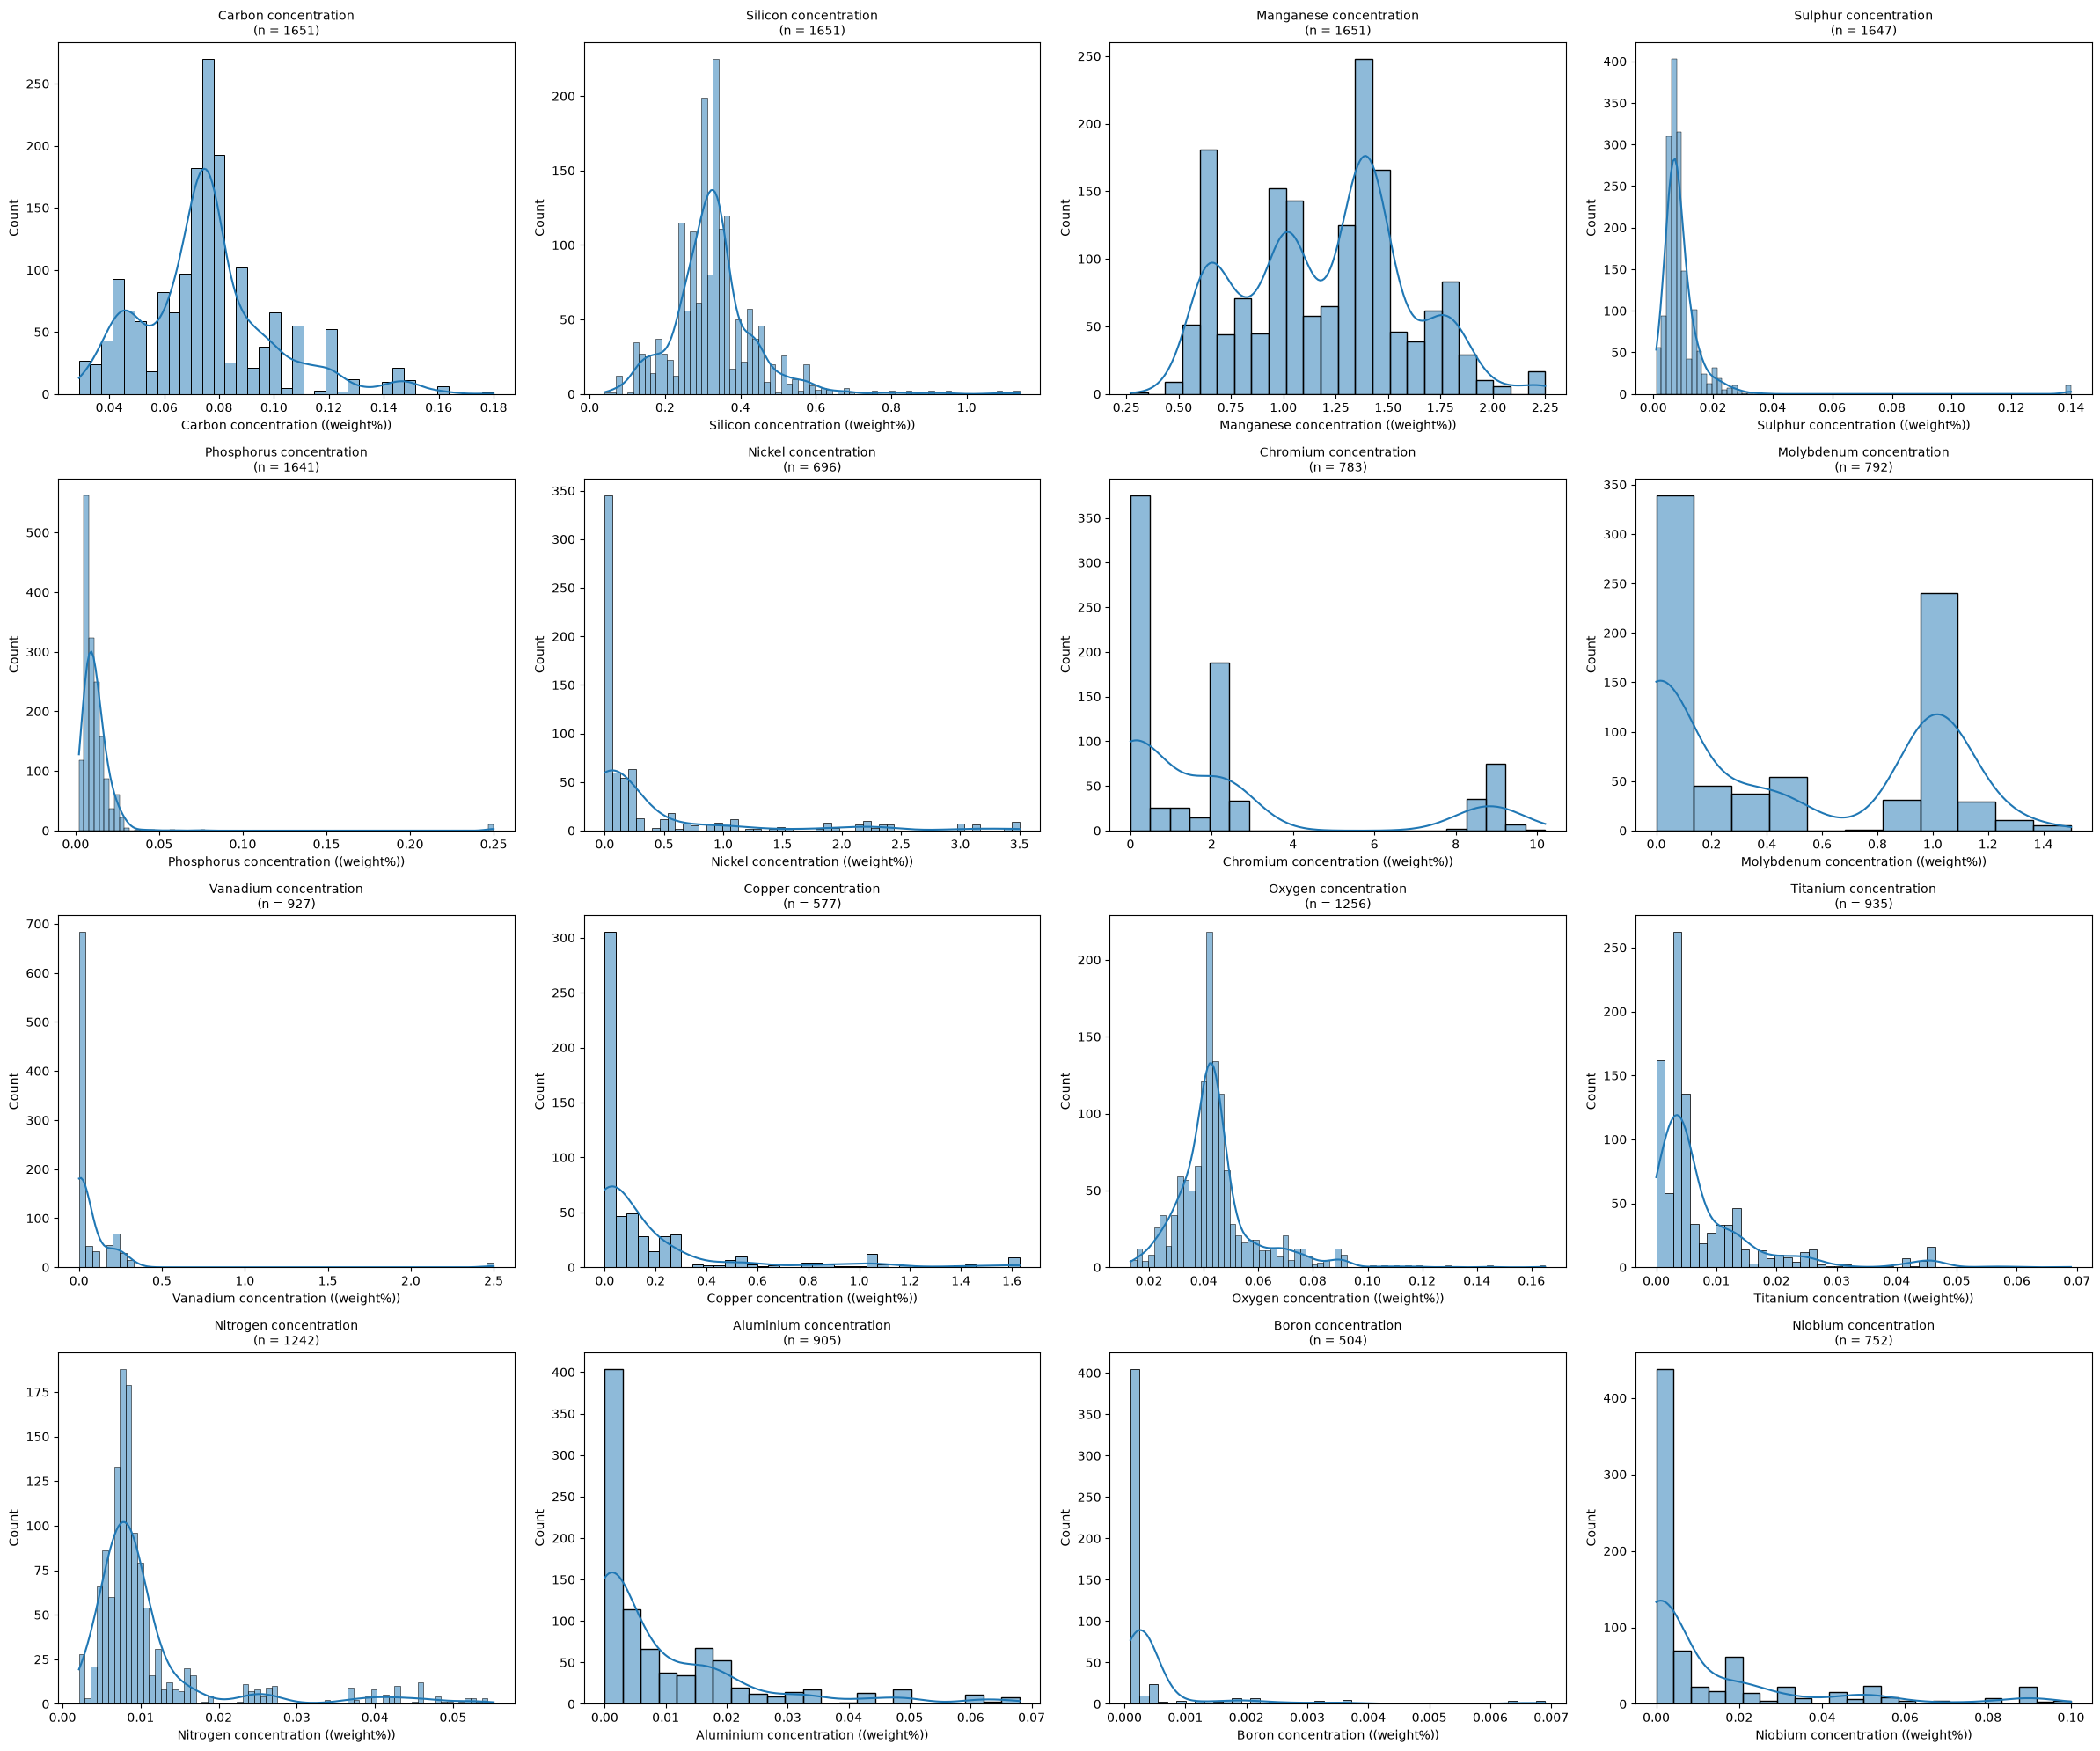

In [9]:
CHEMISTRY = update_liste(CHEMISTRY)


ncols = 4  # nb de graphiques par ligne
nrows = -(-len(CHEMISTRY) // ncols)  # division arrondie vers le haut

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

for ax, t in zip(axes.flat, CHEMISTRY):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    unit = correspondance_between_names_units.loc[
        correspondance_between_names_units['Feature'] == t, 'Unit'
    ].values[0]
    ax.set_xlabel(t if pd.isna(unit) else f"{t} ({unit})")

# masquer les cases vides
for ax in axes.flat[len(CHEMISTRY):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Nous remarquons quelques éléments intéressants pour les concentration moléculaires ou chimiques. Certaines d'entre-elles ont un très grand nombre de 0.Même si l'énoncé explique qu'il y a des valeurs non rapporté, mais cela n'empêche pas de remplir "0" ou ne le mentionne pas quand l'auteur n'ajoute pas l'élément. On repère notamment ces éléments : le nickel, le chromium, le molybdenium, le vanadium, le copper, le titanium, l'aluminium, le niobium et le boron.

Les autres concentrations en manquent pas beaucoup, moins de 30% et ont une répartition bien étendu. Nous allons donc les imputer par la médiane pour ces features : le sulphur, le phorphorus, l'oxygène et le nitrogène. Juste pour les deux derniers, leur teneur dépend surtout du procédé : protection par laitier, flux ou gaz. Ainsi la médiane sera calculée par type de soudage (MMA, SA, FCA…) est donc la meilleure estimation simple.

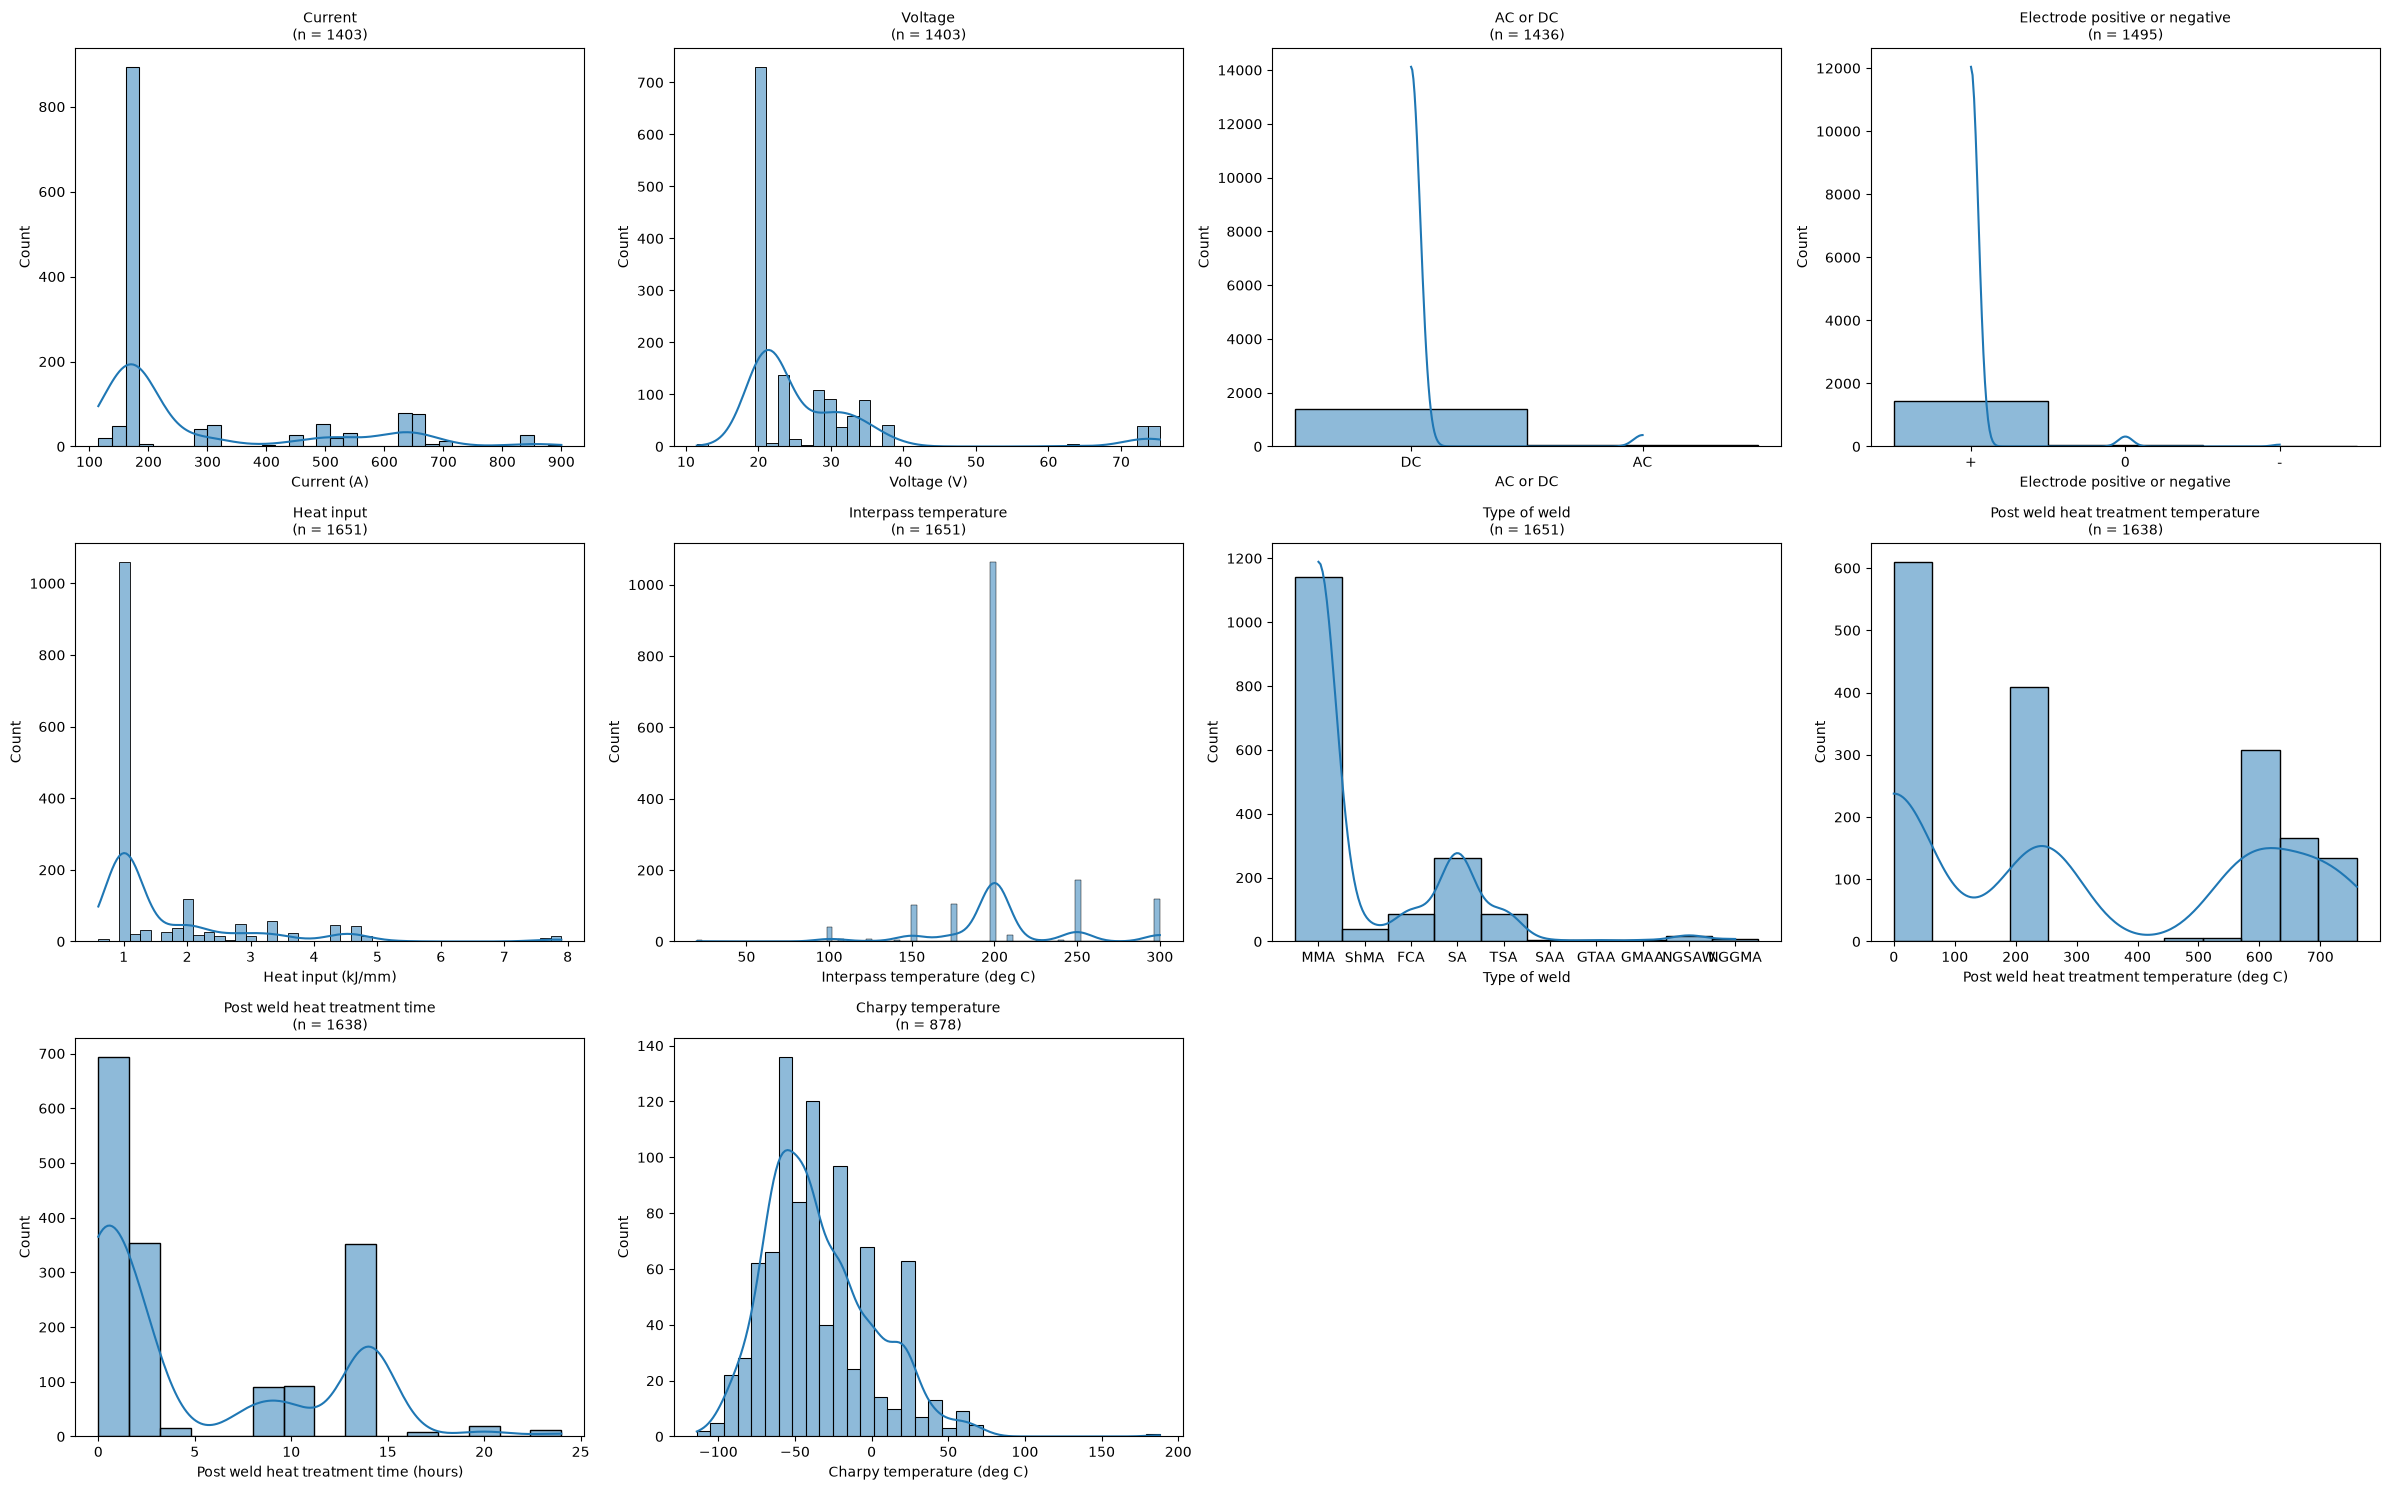

In [10]:
LIST = [col for col in df.columns.tolist() if col not in TARGETS + [ID_COL] + CHEMISTRY]

ncols = 4  # nb de graphiques par ligne
nrows = -(-len(LIST) // ncols)  # division arrondie vers le haut

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)

for ax, t in zip(axes.flat, LIST):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    unit = correspondance_between_names_units.loc[
        correspondance_between_names_units['Feature'] == t, 'Unit'
    ].values[0]
    ax.set_xlabel(t if pd.isna(unit) else f"{t} ({unit})")

# masquer les cases vides
for ax in axes.flat[len(LIST):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Ici pour `Current` et `Voltage`, on l'imputera par la médiane. 

Pour les colonnes `AC/DC` et `Electrode positive or negative`, nous pourrons les combiner en une seule variable (par exemple : DC-, DC+ ou AC). Pour le traitement thermique, nous pouvons directement supprimer les 13 lignes vides, car ils proviennent du même article.

Nous allons juste traiter le changement de `Type of weld` et la suppression des lignes inutiles pour le PWHTT. Le reste qui concerne l'imputation est écrit dans une *class* dans le fichier `utils.py`, et utilisé à la suite. Ces derniers apprennent des éléments sur les données, donc sera lancer après le split des données, et une fois par target disponible.

In [11]:
df["Type of weld"] = df["Type of weld"].replace({"ShMA": "MMA"})
df = df[df["Post weld heat treatment temperature"].notna()]          # retire les 13 lignes Gar&K

## 2. Outliers

In [12]:
FEATURES_NUM = update_liste(PROCESS_NUM + CHEMISTRY)
TARGETS = update_liste(TARGETS)

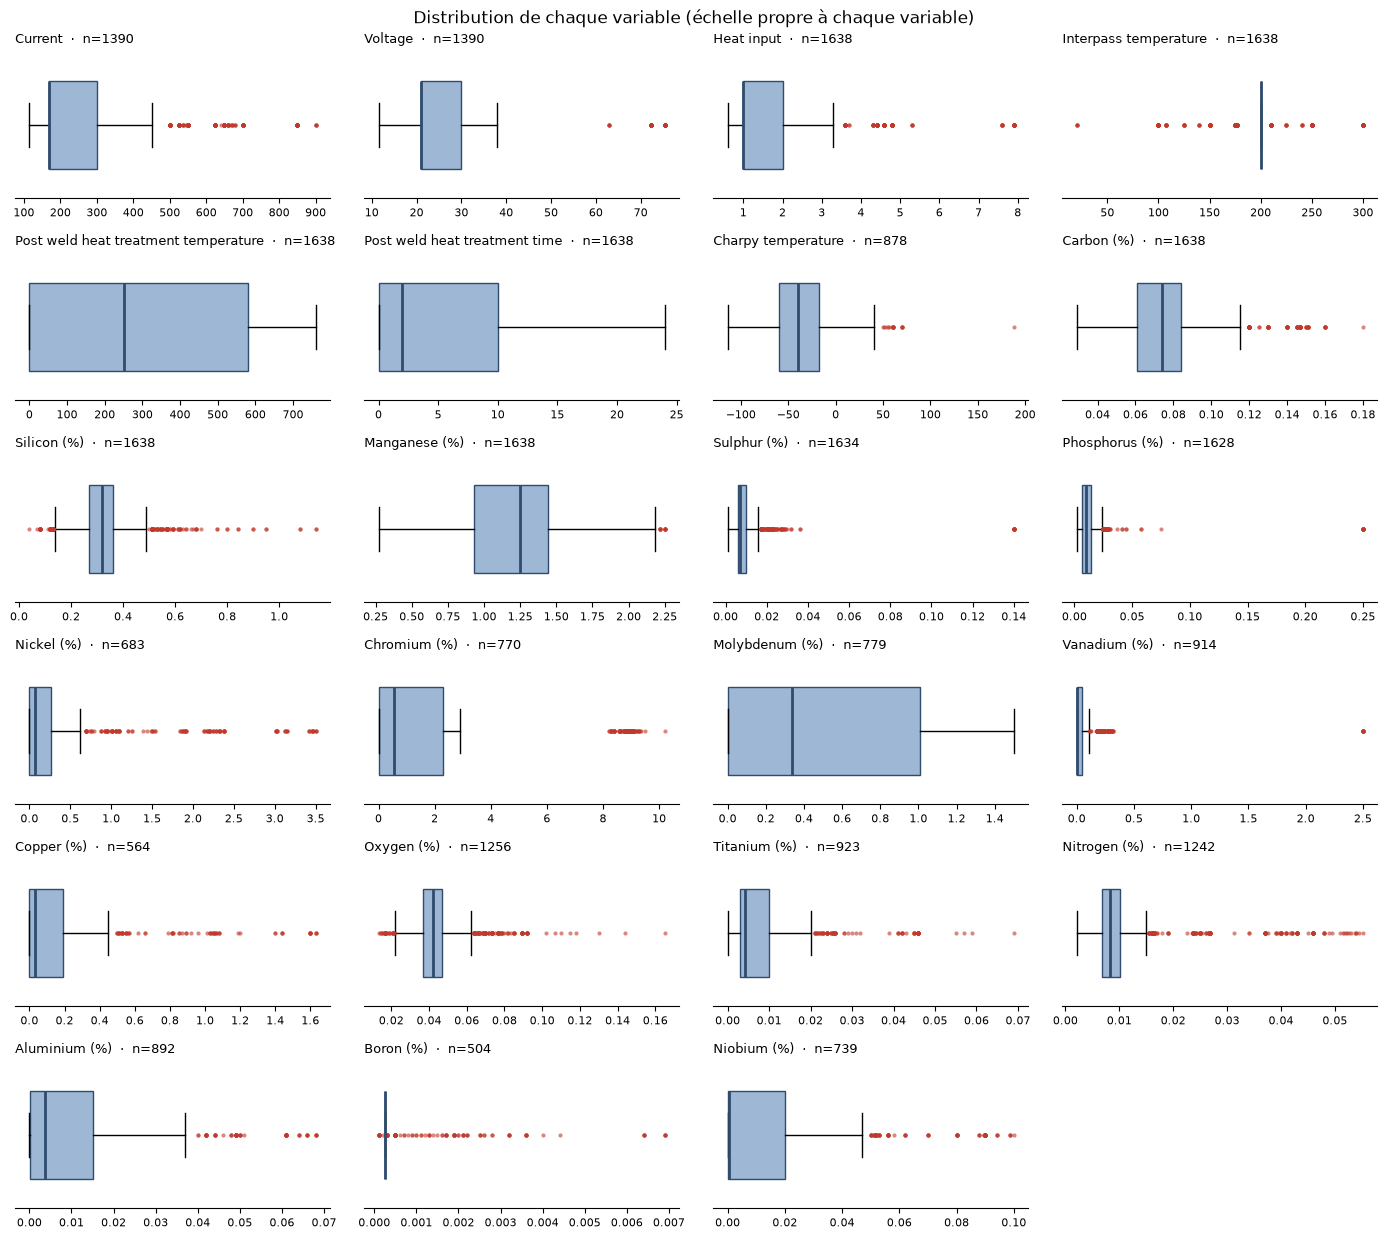

In [13]:
cols = FEATURES_NUM

ncol = 4
nrow = int(np.ceil(len(cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.1 * nrow))
for ax, c in zip(axes.flat, cols):
    s = df[c].dropna()
    ax.boxplot(s, orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#9db7d5", edgecolor="#2f4b6e"),
               medianprops=dict(color="#2f4b6e", linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor="#c0392b",
                               markeredgecolor="none", alpha=0.6))
    ax.set_title(f"{c.replace(' concentration', ' (%)')}  ·  n={len(s)}", fontsize=9, loc="left")
    ax.set_yticks([])
    ax.tick_params(axis="x", labelsize=8)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.suptitle("Distribution de chaque variable (échelle propre à chaque variable)")
fig.tight_layout()
plt.show()

Pour connaître la cohérence des valeurs numériques, nous nous référons au tableau d'information issu de l'article de Tracey Cool, **_The yield and ultimate tensile strength of steel welds_**. L'autrice donne la table 1, indiquant dans quelle intervalle devrait se trouver chaque variable. 

Les intervalles données ne sont pas absolue, nous autorisons des valeurs qui dépasse peu des extrémités et cohérentes en terme d'ordre de grandeur. 

Parmi les boîtes à moustache, nous repérons une valeur abbérante pour la concentration de vanatium qui est de 2,5 (en weight%). Or Tracey Cool indique que ce dernier doit être compris dans l'intervalle [0 ; 0.24]. Ce dernier peut être une erreur de saisie d'unité, nous allons donc le convertir en %weight.

In [14]:
mask_v = (df["Vanadium concentration"] == 2.5)
df.loc[mask_v, "Vanadium concentration"] = 0.00025

Pour éviter les erreurs de saisie, on va vérifier cela. Il faut savoir qu'expérimentalement il est difficile de mesurer des concentrations de moins 0.00001%, c'est pour ça qu'on va les chercher.

Ainsi, nous pouvons les considérer comme une erreur de saisie en ppm et les reconvertir en %weight. (Il faut savoir que ces lignes sont des traitements à part, car ils concernent qu'une petite partie des données)

In [15]:
# Colonnes d'origine en ppm (converties en % massique dans le notebook 1)
PPM_COLS = ["Oxygen concentration", "Titanium concentration", "Nitrogen concentration",
            "Aluminium concentration", "Boron concentration", "Niobium concentration",
            "Tin concentration", "Arsenic concentration", "Antimony concentration"]
PPM_COLS = [c for c in PPM_COLS if c in df.columns]   # ignore les colonnes déjà supprimées

SEUIL_PCT = 1e-5   # 0,1 ppm exprimé en % : en dessous, la valeur a été saisie en % au lieu de ppm

# --- Détection ---
suspects = []
for col in PPM_COLS:
    m = (df[col] > 0) & (df[col] < SEUIL_PCT)
    if m.any():
        resume = (df.loc[m].groupby("Weld ID")[col]
                    .agg(n="count", valeurs=lambda s: sorted(s.unique())))
        resume.insert(0, "Variable", col)
        suspects.append(resume.reset_index())

suspects = pd.concat(suspects, ignore_index=True) if suspects else pd.DataFrame()
display(suspects)

,Weld ID,Variable,n,valeurs
0,PantK-1990,Titanium concentration,16,[5e-07]
1,EPRI-TR-1013,Aluminium concentration,10,"[4e-07, 5e-07, 1.2999999999999998e-06, 1.4e-06]"
2,PantK-1990,Aluminium concentration,16,[5e-07]


In [16]:
# --- Correction : ×10 000 (valeurs saisies en % dans une colonne en ppm, puis divisées à tort) ---
for col in PPM_COLS:
    m = (df[col] > 0) & (df[col] < SEUIL_PCT)
    if m.any():
        df.loc[m, col] = df.loc[m, col] * 10_000
        print(f"{col:28s} : {m.sum():3d} valeurs corrigées "
              f"(séries : {', '.join(df.loc[m, 'Weld ID'].unique())})")

# Vérification
assert all(((df[c] > 0) & (df[c] < SEUIL_PCT)).sum() == 0 for c in PPM_COLS)

Titanium concentration       :  16 valeurs corrigées (séries : PantK-1990)
Aluminium concentration      :  26 valeurs corrigées (séries : PantK-1990, EPRI-TR-1013)


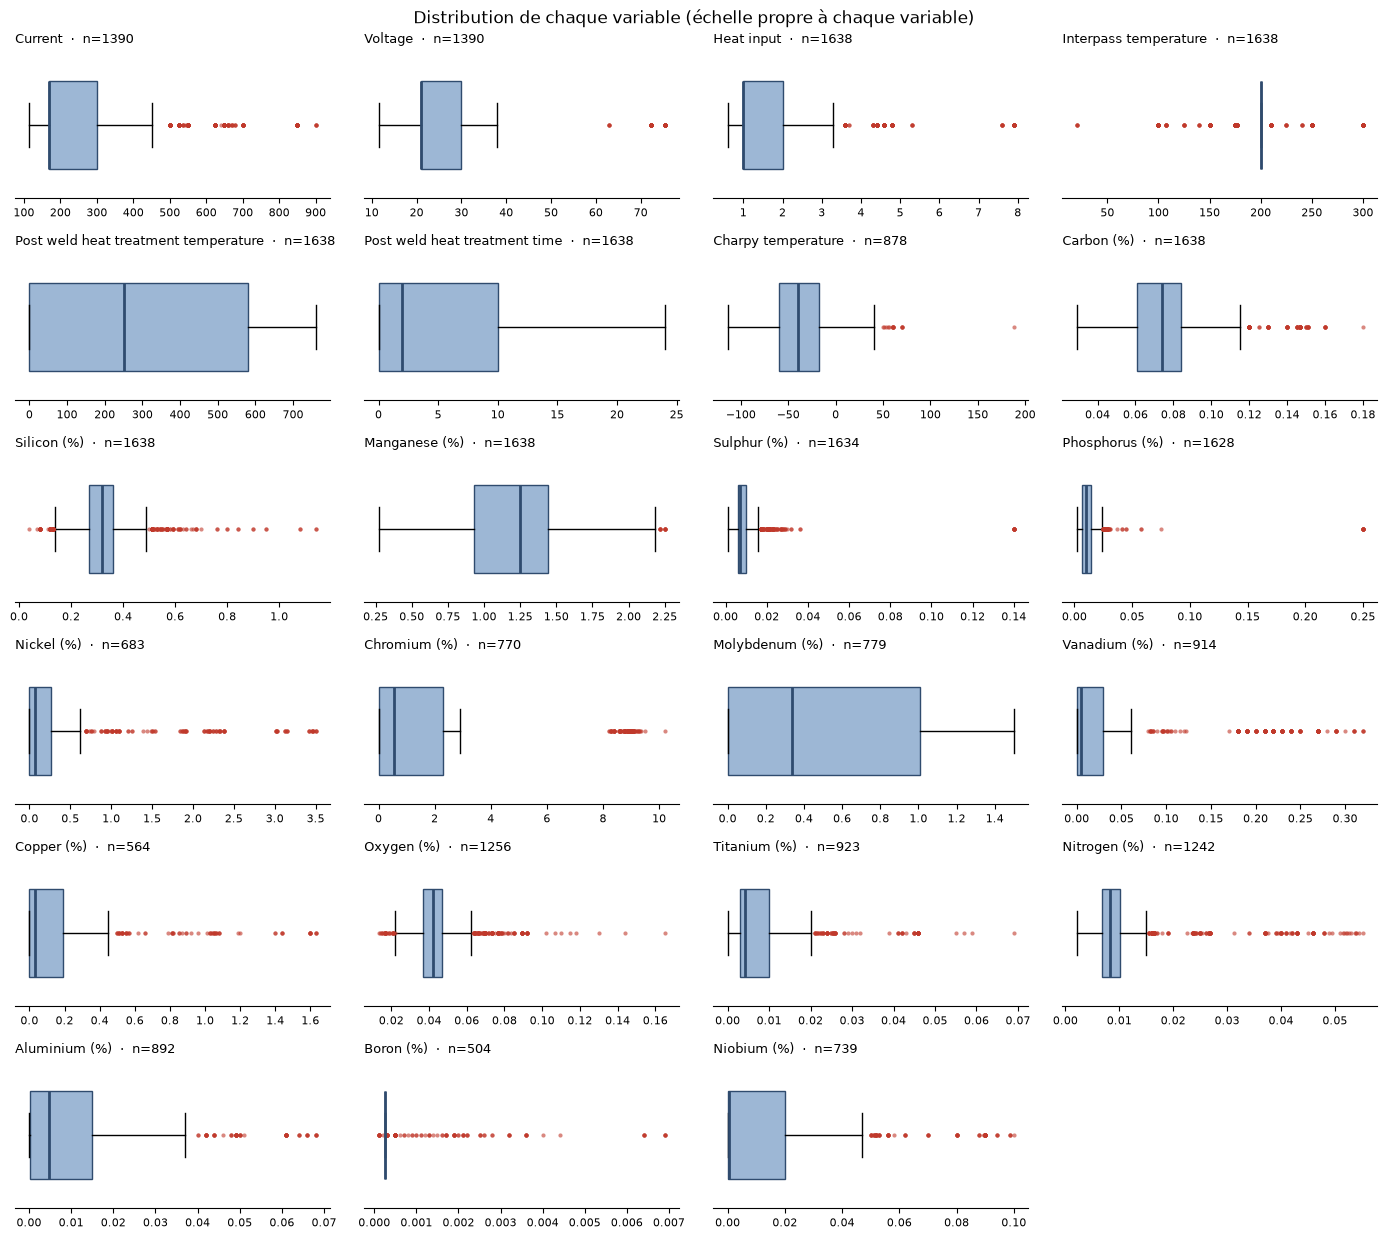

In [17]:
cols = FEATURES_NUM

ncol = 4
nrow = int(np.ceil(len(cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.1 * nrow))
for ax, c in zip(axes.flat, cols):
    s = df[c].dropna()
    ax.boxplot(s, orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#9db7d5", edgecolor="#2f4b6e"),
               medianprops=dict(color="#2f4b6e", linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor="#c0392b",
                               markeredgecolor="none", alpha=0.6))
    ax.set_title(f"{c.replace(' concentration', ' (%)')}  ·  n={len(s)}", fontsize=9, loc="left")
    ax.set_yticks([])
    ax.tick_params(axis="x", labelsize=8)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.suptitle("Distribution de chaque variable (échelle propre à chaque variable)")
fig.tight_layout()
plt.show()

Après avoir traitée manuellement les outliers visibles, nous pouvons regarder celle qui sont statistiquement abbérantes. On utilisera la méthode de Tukey (1977) vue en CM0 : une valeur est atypique si elle est hors de $[Q_1 - 1.5\,IQR \; ; \; Q_3 + 1.5\,IQR]$.

Le cours distingue deux cas : **erreur de mesure** (→ traiter comme une valeur manquante) ou **situation extraordinaire** (→ garder). Ici, beaucoup de « outliers » statistiques sont des **aciers volontairement alliés** (ex. soudures 9Cr-1Mo avec ~9 % de chrome) ou des traitements thermiques particuliers : ce sont des cas réels, pas des erreurs. On **détecte sans supprimer**, et on vérifie seulement les valeurs physiquement impossibles.

In [18]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "nb outliers IQR": df[FEATURES_NUM + TARGETS].apply(iqr_outliers),
    "min": df[FEATURES_NUM + TARGETS].min(),
    "médiane": df[FEATURES_NUM + TARGETS].median(),
    "max": df[FEATURES_NUM + TARGETS].max(),
    "unité": correspondance_between_names_units.loc[correspondance_between_names_units['Feature'].isin(FEATURES_NUM + TARGETS), 'Unit' ].to_list(),
}).sort_values("nb outliers IQR", ascending=False)
out

,nb outliers IQR,min,médiane,max,unité
Interpass temperature,574,20.0000,200.00000,300.0000,(weight%)
Current,296,115.0000,170.00000,900.0000,(weight%)
Vanadium concentration,187,0.0000,0.00500,0.3200,(weight%)
Nitrogen concentration,172,0.0021,0.00820,0.0552,deg C
Heat input,157,0.6000,1.00000,7.9000,(weight%)
Oxygen concentration,156,0.0132,0.04230,0.1650,V
Silicon concentration,153,0.0400,0.32000,1.1400,(weight%)
Nickel concentration,126,0.0000,0.06800,3.5000,(weight%)
Sulphur concentration,121,0.0010,0.00700,0.1400,(weight%)
Chromium concentration,120,0.0000,0.55500,10.2000,(weight%)


In [19]:
# Contrôles de cohérence physique (valeurs impossibles = erreurs)
checks = {
    "concentration négative": (df[CHEMISTRY] < 0).any(axis=1),
    "UTS < limite d'élasticité": df["Ultimate tensile strength"] < df["Yield strength"],
    "pourcentage > 100": (df[["Elongation", "Reduction of Area"]] > 100).any(axis=1),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="nb lignes")

concentration négative       0
UTS < limite d'élasticité    0
pourcentage > 100            0
Name: nb lignes, dtype: int64

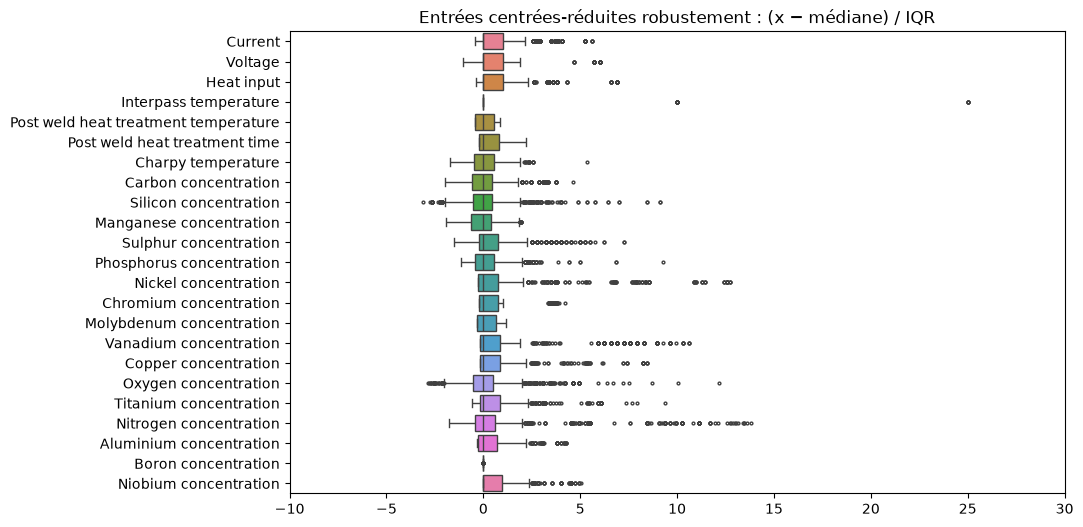

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
z = (df[FEATURES_NUM] - df[FEATURES_NUM].median()) / (df[FEATURES_NUM].quantile(.75) - df[FEATURES_NUM].quantile(.25)).replace(0, 1)
sns.boxplot(data=z, orient="h", ax=ax, fliersize=2)
ax.set_xlim(-10, 30)
ax.set_title("Entrées centrées-réduites robustement : (x − médiane) / IQR")
plt.show()

Maintenant, on peut déduire que ces derniers sont bien dans leur borne de valeurs.

## 3. Feature engineering : pour donner plus d'information et avoir une forme adapter pour la prédiction

Maintenant on arrive à la dernière étape du pré-processing, qui consiste à faire du feature engineering. Pour augmenter la cohérence et la qualité de notre prédiction, nous allons chercher à trouver ou créer des nouvelles variables pertinentes.

### 3.1) Création d'une nouvelle variable : ``Charpy conforme``

On remarque que la cible `Charpy impact toughness` est une variable qui dépend fortement des conditions d'essaies, c'est-à-dire la `Charpy temperature`. Dans ce cas, il n'est pas indicatif de prédire un indicateur sans tenir compte des contitions de test. 

Pour régler ce problème, nous pouvons nous aider de la littérature pour créer une nouvelle cible `Charpy conforme` afin de savoir si la charpy est conforme ou non suivant ces conditions de tests. 

> L'énergie Charpy dépend fortement de la température d'essai, qui est une condition de test et non une propriété de la soudure : elle augmente avec la température selon une courbe en S, la transition ductile-fragile [1]. On la remplace par un label de conformité à l'exigence **≥ 47 J à −40 °C**. Le seuil de 47 J est celui de la norme EN ISO 2560 (système A) [2] ; la température de −40 °C a été choisie car elle correspond à la médiane des températures d'essai de la base.
>
> Les données Charpy sont de deux types : des essais classiques (énergie mesurée à une température donnée) et, pour la plupart des **températures de transition**, c'est-à-dire la température à laquelle la soudure atteint 28 J ou 100 J (lignes horizontales du nuage énergie-température).
>
> L'énergie augmentant avec la température [1], chaque essai donne :
> - **conforme (1)** si E ≥ 47 J à T ≤ −40 °C ;
> - **non conforme (0)** si E < 47 J à T ≥ −40 °C ;
> - **inconnu (NaN)** sinon, ou en l'absence d'essai Charpy.
>
> Pour les soudures disposant à la fois de T(28 J) et de T(100 J), la température T(47 J) est estimée par interpolation linéaire, et la soudure est conforme si T(47 J) ≤ −40 °C. Ce résultat remplace la règle précédente pour toutes les lignes de la soudure. Les 4 soudures où T(100 J) < T(28 J), physiquement incohérentes, restent inconnues.
>
> Cette règle de déduction est un choix méthodologique propre à ce projet, fondé sur la monotonie de la courbe de transition. Elle reste une approximation : les mesures Charpy sont dispersées, en particulier dans la zone de transition [1], et l'interpolation linéaire simplifie une courbe en S.
>
> Résultat : 464 lignes conformes, 105 non conformes, le reste inconnu (données non labélisées pour le semi-supervisé).
>
> **Références**
>- [1] T. Cool, thèse de doctorat, University of Cambridge, 1996, chapitre 6 (§ 6.4–6.5, figure 6.16).
>- [2] EN ISO 2560 : Produits consommables pour le soudage — Électrodes enrobées pour le soudage manuel à l'arc des aciers non alliés et à grains fins — Classification.

356 valeurs à 100 J et 118 à 28 J sur 878 valeurs Charpy


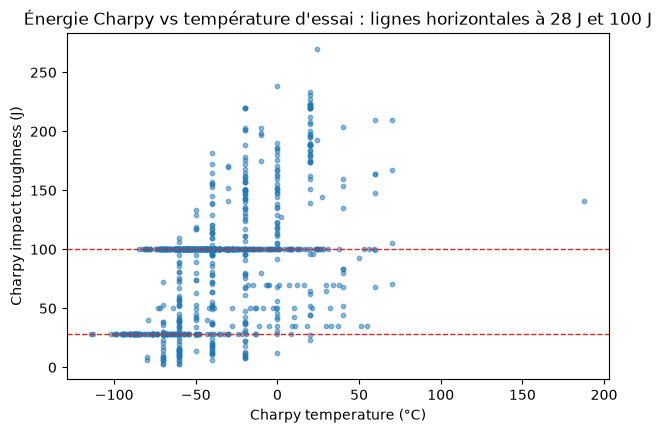

In [21]:
c = df["Charpy impact toughness"]
print(f"{(c == 100).sum()} valeurs à 100 J et {(c == 28).sum()} à 28 J sur {c.notna().sum()} valeurs Charpy")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["Charpy temperature"], c, s=10, alpha=.5)
for level in (28, 100):
    ax.axhline(level, ls="--", color="C3", lw=1)
ax.set_xlabel("Charpy temperature (°C)"); ax.set_ylabel("Charpy impact toughness (J)")
ax.set_title("Énergie Charpy vs température d'essai : lignes horizontales à 28 J et 100 J")
plt.show()

In [22]:
SEUIL_E = 47     # énergie minimale exigée (J)
SEUIL_T = -40    # température de l'exigence (°C)
T = "Charpy temperature"
E = "Charpy impact toughness"

# Colonnes de résultats d'essais ; tout le reste décrit la soudure
RESULTATS = ["Yield strength", "Ultimate tensile strength", "Elongation", "Reduction of Area",
             T, E, "Hardness", "50 % FATT", "Primary ferrite in microstructure",
             "Ferrite with second phase", "Acicular ferrite", "Martensite",
             "Ferrite with carbide aggreagate"]
DESCRIPTION = [c for c in df.columns if c not in RESULTATS]   # AVANT de créer le label

# 1) Règle ligne par ligne
conforme     = (df[E] >= SEUIL_E) & (df[T] <= SEUIL_T)
non_conforme = (df[E] <  SEUIL_E) & (df[T] >= SEUIL_T)
df["Charpy conforme"] = np.select([conforme, non_conforme], [1, 0], default=np.nan)

# 2) Soudures ayant T(28 J) et T(100 J) : interpolation de T(47 J)
cle  = df.groupby(DESCRIPTION, dropna=False).ngroup()
t28  = df[T].where(df[E] == 28).groupby(cle).transform("mean")
t100 = df[T].where(df[E] == 100).groupby(cle).transform("mean")
t47  = t28 + (SEUIL_E - 28) / (100 - 28) * (t100 - t28)
t47[t100 < t28] = np.nan          # courbe incohérente : on ne conclut pas

ok = t47.notna()
df.loc[ok, "Charpy conforme"] = (t47[ok] <= SEUIL_T).astype(int)

# 3) Suppression des colonnes Charpy brutes, à la fin
df = df.drop(columns=[T, E])
df["Charpy conforme"].value_counts(dropna=False)


Charpy conforme
NaN    1069
1.0     464
0.0     105
Name: count, dtype: int64

### 3.2) Construction de nouvelles variables

Dans cette partie, on fera le choix de définir deux variables supplémentaires à ajouter dans notre base de données : le carbonne équivalent IIW (`CE_IIW`) et le paramètre de revenu de Hollomon-Jaffe (`Hollomon_Jaffe`).

L'intérêt d'avoir ces variables est de pouvoir regrouper plusieurs colonnes en un indicateur unique, justifié par la métallurgie du soudage, ce qui limite la dimension du problème.

Cependant, nous ferons la construction après l'imputation des données. Dû au fait qu'on a 5 cibles différentes, l'imputation sera également différente une par une, d'où la nécessité de refaire la construction après chaque imputation. Pour cela, nous avons stocké la fonction dans `utils_pipeline.py` pour alléger notre code et pouvoir l'importer plus tard. 

Une description de chacun des variables à construire sera faite ci-dessous, mais en dernière partie nous analyserons la corrélation entre la nouvelle variable et les variables bruts. Il sera néssaire pour savoir si on garde pour cette nouvelle variable. On a au total deux candidats.

#### A. Carbone équivalent IIW (`CE_IIW`)

**Explication.** Le carbone équivalent résume en une seule valeur l'effet combiné des éléments d'alliage sur la trempabilité de l'acier, donc sur sa dureté et sa résistance mécanique. Les éléments sont pondérés selon leur efficacité relative par rapport au carbone. Cet indicateur est la formule de référence de l'*International Institute of Welding* (IIW) pour évaluer la soudabilité des aciers.

**Formule** (teneurs en % massique) :

$$CE_{IIW} = C + \frac{Mn}{6} + \frac{Cr + Mo + V}{5} + \frac{Ni + Cu}{15}$$

**Référence.** Dearden, J. et O'Neill, H. (1940). *A guide to the selection and welding of low alloy structural steels*. Transactions of the Institute of Welding, 3, 203-214. Formule adoptée par l'IIW (1967).

#### B. Paramètre de revenu de Hollomon-Jaffe (`Hollomon_Jaffe`)

**Explication.** La température et la durée du traitement thermique après soudage (PWHT) agissent ensemble : une hausse de l'une ou de l'autre réduit la résistance (Cool et al., 1997, section 9). Le paramètre de Hollomon-Jaffe fusionne les deux en une seule variable équivalente « temps-température ». Deux traitements différents qui donnent la même valeur de $P$ conduisent à un état de revenu comparable. Pour les soudures sans traitement, on fixe $P = 0$ et on ajoute l'indicateur binaire `PWHT_applied`, car $\log_{10}(0)$ n'est pas défini.

**Formule** :

$$P = T \cdot \left( C + \log_{10} t \right)$$

avec $T$ la température de revenu en kelvin ($T_{K} = T_{°C} + 273{,}15$), $t$ la durée en heures et $C \approx 20$ une constante propre aux aciers faiblement alliés.

**Références.**
- Hollomon, J.H. et Jaffe, L.D. (1945). *Time-temperature relations in tempering steel*. Transactions of the AIME, 162, 223-249.
- Cool, T., Bhadeshia, H.K.D.H. et MacKay, D.J.C. (1997). *The yield and ultimate tensile strength of steel welds*. Materials Science and Engineering A, 223, 186-200.

#### C. Pré-visualisation de la proximité entre les variables construites et les variables bruts

In [23]:
def add_features_raw(df):
    df = df.copy()
    # CE : NaN si une composante manque (pas de fillna)
    df["CE_IIW"] = (df["Carbon concentration"]
                    + df["Manganese concentration"] / 6
                    + (df["Chromium concentration"] + df["Molybdenum concentration"]
                       + df["Vanadium concentration"]) / 5
                    + (df["Nickel concentration"] + df["Copper concentration"]) / 15)

    Tc = df["Post weld heat treatment temperature"]
    t  = df["Post weld heat treatment time"]
    known   = Tc.notna() & t.notna()
    applied = known & (Tc > 0) & (t > 0)

    df["PWHT_applied"] = np.where(known, applied.astype(float), np.nan)
    df["Hollomon_Jaffe"] = np.where(applied, (Tc + 273.15) * (20 + np.log10(t.where(t > 0, 1))),
                                    np.where(known, 0.0, np.nan))
    return df

df_raw_feat = add_features_raw(df)          # df = données brutes, avant imputation

cols = ["Carbon concentration", "Manganese concentration", "Chromium concentration",
        "Molybdenum concentration", "Vanadium concentration", "Nickel concentration",
        "Copper concentration", "Post weld heat treatment temperature",
        "Post weld heat treatment time", "CE_IIW", "Hollomon_Jaffe"]
sub = df_raw_feat[cols]

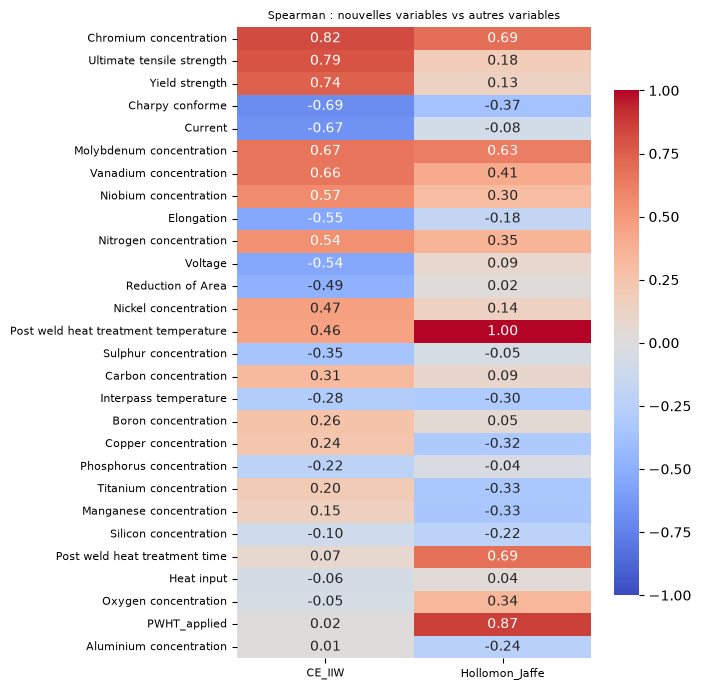

In [24]:
new_vars = ["CE_IIW", "Hollomon_Jaffe"]

num = df_raw_feat.select_dtypes("number").drop(columns=["groupe"], errors="ignore")

corr = num.corr(method="spearman")
n = num.notna().astype(int).T @ num.notna().astype(int)

# Lignes = autres variables, colonnes = nouvelles variables
c = corr[new_vars].drop(index=new_vars)
c = c.reindex(c["CE_IIW"].abs().sort_values(ascending=False).index)   # tri par |rho| avec CE

plt.figure(figsize=(7,7))
sns.heatmap(c, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            cbar_kws={"shrink": 0.8})
plt.title("Spearman : nouvelles variables vs autres variables", fontsize = 8)
plt.xticks(rotation=0, fontsize = 8)
plt.yticks(fontsize = 8)
plt.tight_layout()
plt.show()

En utilisant les données sans imputation, on peut déjà voir que la corrélation entre `Hollomon_Jaffe` et le `Post weld heat treatment temperature`est fortement corrélé à 1. Ceci dit, pour rester simple, nous allons ainsi abandonner `Hollomon_Jaffe` pour garder plus de simplicité dans nos données.

A l'inverse la variable `CE_IIW` est moins impactée, même peu corrélés aux autres variables de concentration. On remarque également que cette dernière présente un lien de corrélation avec l'`Ultimate tensile strength` et le `Yield strength`. Cela est plutôt rassurant, car c'est un bon signe pour les prédictions qui arrivent.

## 4. Analyse descriptive finale 

### 4.0) Actualisation des tables de données

Cette partie est faite pour actualiser la table de correspondance entre les variables et leur unités.

In [25]:
LIST_DF = df.columns.tolist()

# Suppression des lignes de features qui ne sont pas dans df
mask_corresp = correspondance_between_names_units['Feature'].isin(LIST_DF)
CORRESP = correspondance_between_names_units[mask_corresp]

# Extraction des noms de features qui sont dans df, mais dans la table de correspondance
FEATURE_CORRESP = CORRESP['Feature'].tolist()
FEATURE_ADD = [f for f in LIST_DF if f not in FEATURE_CORRESP]

print(FEATURE_ADD)

['Charpy conforme']


In [26]:
# Ajout de la ligne sur le "Chary conforme" dans la table de correspondance
CORRESP = pd.concat([
    CORRESP,
    pd.DataFrame([{
        "Feature": "Charpy conforme",
        "Unit": np.nan,
        "Role": "Quality indicator",
        "Types de variables": "float64"
    }])
], ignore_index=True)

### 4.1) Distribution des cibles

In [27]:
print(TARGETS)
TARGETS[-1] = "Charpy conforme"
print(TARGETS)

['Yield strength', 'Ultimate tensile strength', 'Elongation', 'Reduction of Area', 'Charpy impact toughness']
['Yield strength', 'Ultimate tensile strength', 'Elongation', 'Reduction of Area', 'Charpy conforme']


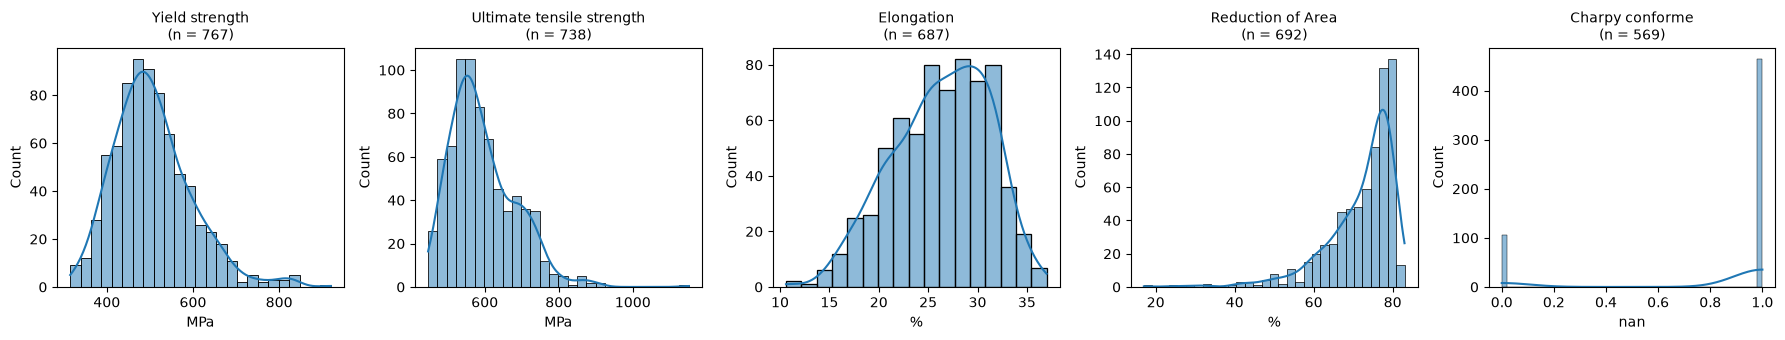

,count,mean,std,min,25%,50%,75%,max
Yield strength,767.0,506.4,91.3,315.0,443.0,494.0,555.0,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,687.0,26.3,4.9,10.6,23.0,26.8,30.0,37.0
Reduction of Area,692.0,72.0,8.8,17.0,68.5,75.0,78.0,83.0
Charpy conforme,569.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0


In [28]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(CORRESP.loc[CORRESP['Feature'] == t, 'Unit'].values[0])
plt.tight_layout()
plt.show()

df[TARGETS].describe().T.round(1)

### 4.2) Corrélations

On utilise la corrélation de **Spearman** (sur les rangs) plutôt que Pearson : elle capte les relations monotones non linéaires. Chaque coefficient est calculé sur les paires de valeurs disponibles (*pairwise*) : les coefficients reposent donc sur des effectifs différents, à garder en tête pour l'interprétation.

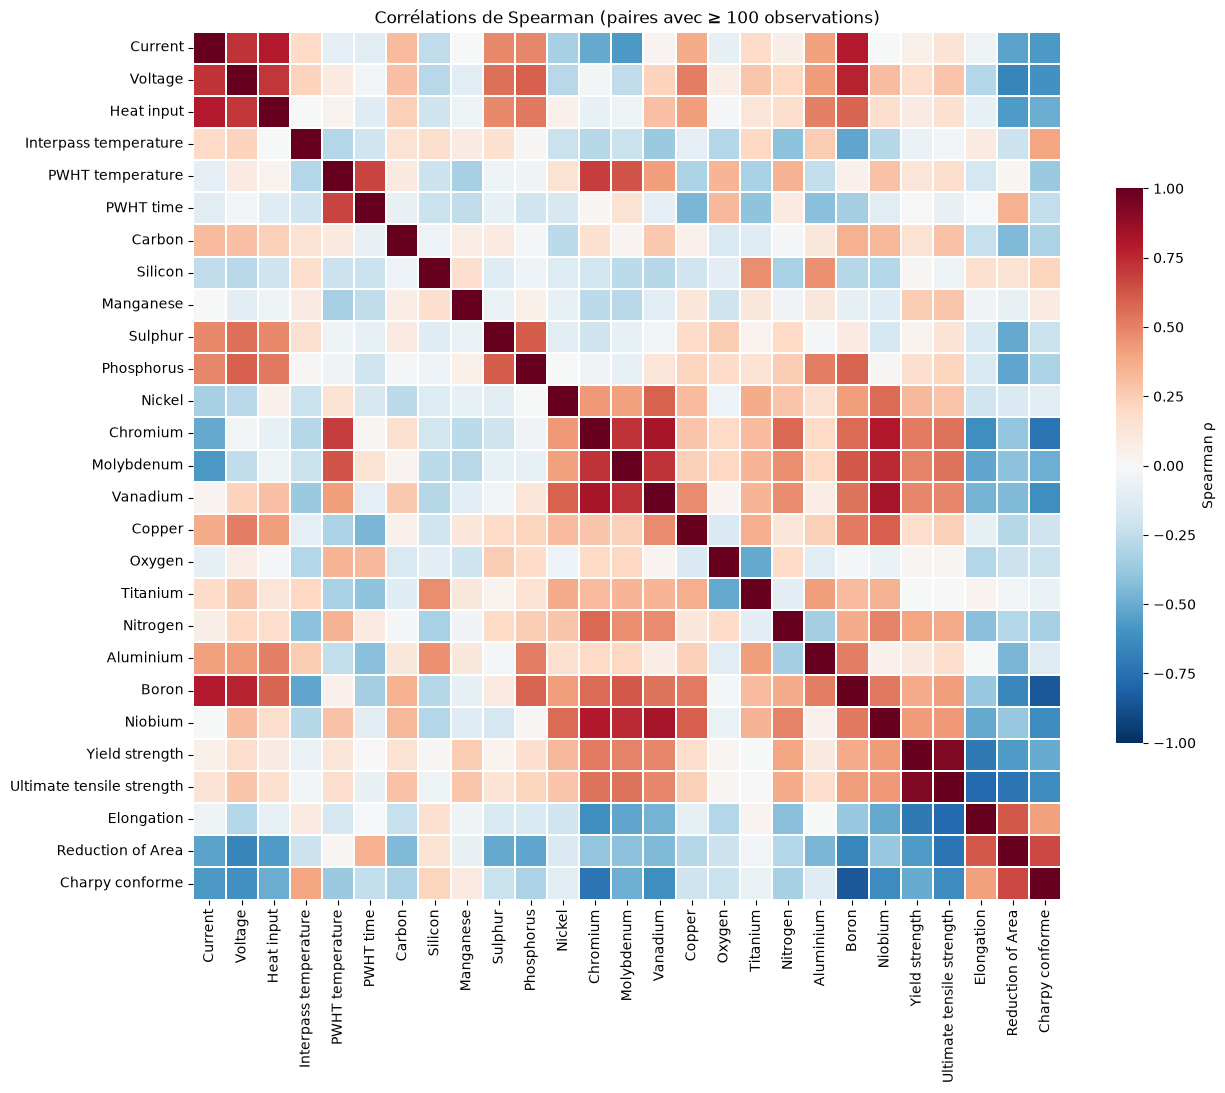

In [29]:
FEATURES_NUM = update_liste(FEATURES_NUM)
corr = df[FEATURES_NUM + TARGETS].corr(method="spearman", min_periods=100)
short = lambda c: c.replace(" concentration", "").replace("Post weld heat treatment", "PWHT")
corr = corr.rename(index=short, columns=short)

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "Spearman ρ"})
plt.title("Corrélations de Spearman (paires avec ≥ 100 observations)")
plt.show()

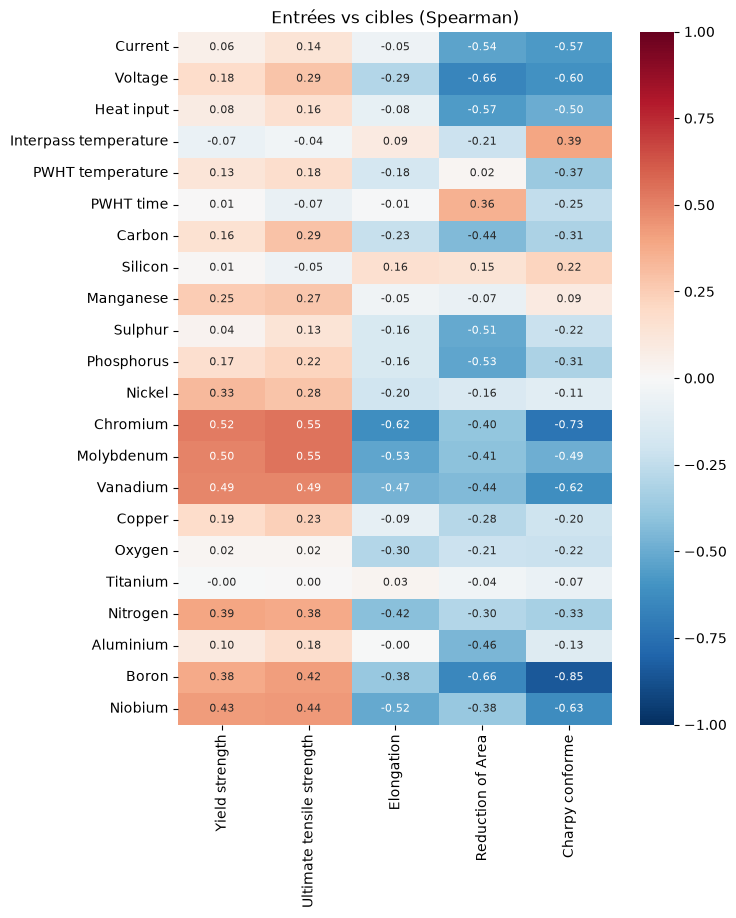

In [30]:
# Corrélation de chaque entrée avec chaque cible
corr_targets = corr.loc[[short(c) for c in FEATURES_NUM], [short(t) for t in TARGETS]]
plt.figure(figsize=(7, 9))
sns.heatmap(corr_targets, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Entrées vs cibles (Spearman)")
plt.show()

**Entre variables d'entrée**
- Trois blocs redondants ressortent : le **procédé** (`Current`, `Voltage`, `Heat input`, ρ ≈ 0,7-0,8), les **éléments d'alliage** (`Cr`, `Mo`, `V`, `Nb`, ρ ≈ 0,7-0,8) et le **revenu** (`PWHT temperature` et `PWHT time`, ρ ≈ 0,65).
- Les aciers très alliés reçoivent aussi les revenus les plus chauds : composition et traitement thermique sont donc confondus.
- Le bore est très corrélé au courant et à la tension. Ce lien n'a pas de justification métallurgique et traduit probablement un effet de source (hypothèse).

**Entre entrées et cibles**
- **Limite d'élasticité et UTS** : portées par `Cr`, `Mo`, `V` et `Nb` (ρ ≈ 0,5), puis `N`, `B` et `Ni` (ρ ≈ 0,3-0,4). Le carbone est peu discriminant (plage étroite).
- **Allongement** : effet inverse de la résistance (`Cr` -0,62, `Mo` -0,53), d'où le compromis résistance/ductilité.
- **Striction** : surtout liée au procédé et aux impuretés (`Voltage` -0,66, `Heat input` -0,57, `P` et `S` ≈ -0,5).
- **Charpy conforme** : baisse avec les alliages (`B` -0,85, `Cr` -0,73) et l'énergie de soudage, et augmente avec la température d'interpasse (+0,39).
- Les variables de revenu ont peu de lien apparent avec la résistance (|ρ| < 0,2), mais leur effet est masqué par la composition.

**Limites**
- Corrélation n'est pas causalité : composition, procédé et revenu varient ensemble.
- Les effectifs varient selon les paires, et Spearman ne détecte que les liens monotones.

**Conséquences**
- Utiliser des modèles robustes à la redondance (forêts, boosting) ou régularisés (Ridge/Lasso).
- Conserver `CE_IIW`, qui synthétise le bloc d'alliage.
- Valider par groupes (`GroupKFold`) et prévoir un modèle par cible.

### 4.3) Analyse en Composantes Principales

**But** : développer de l'intuition sur la structure des **entrées** (le sujet le demande explicitement) : quelles variables varient ensemble, y a-t-il des groupes de soudures, des individus atypiques ?

Choix (cours CM2) :
- ACP sur les **entrées uniquement** (non supervisée ; les cibles serviront juste à colorer les points) ;
- variables **standardisées** : sinon les variables en ppm ou en °C (grandes variances) domineraient celles en % massique (cf. l'exemple *USArrests* du cours, où `Assault` écrase tout sans standardisation) ;
- **imputation par la médiane** avant l'ACP, uniquement pour cette exploration (l'ACP ne gère pas les NaN). Elle écrase la variance des variables très manquantes : à mentionner dans le rapport comme limite.
- nombre de composantes : règle des **80 % de variance cumulée**, **coude** de l'histogramme, **critère de Kaiser** (λ > 1 sur données centrées-réduites).

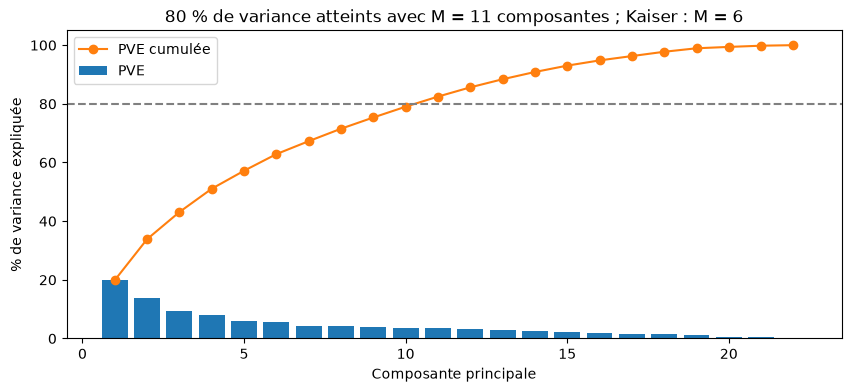

In [31]:
X_pca_in = df[FEATURES_NUM ]
pca_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA()),
])
scores = pca_pipe.fit_transform(X_pca_in)
pca = pca_pipe.named_steps["pca"]
pve = pca.explained_variance_ratio_
eig = pca.explained_variance_

M80 = int(np.argmax(np.cumsum(pve) >= 0.80) + 1)
M_kaiser = int((eig > 1).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(pve) + 1), pve * 100, label="PVE")
ax.plot(range(1, len(pve) + 1), np.cumsum(pve) * 100, "o-", color="C1", label="PVE cumulée")
ax.axhline(80, ls="--", color="grey")
ax.set_xlabel("Composante principale"); ax.set_ylabel("% de variance expliquée")
ax.set_title(f"80 % de variance atteints avec M = {M80} composantes ; Kaiser : M = {M_kaiser}")
ax.legend()
plt.show()

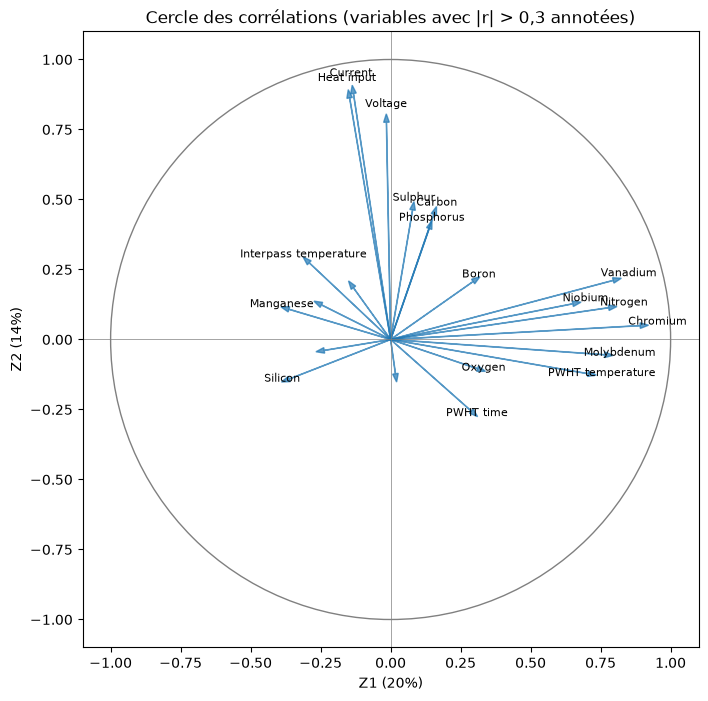

In [32]:
# Cercle des corrélations Z1/Z2 : corr(Z_m, X_j)
X_std = pca_pipe[:-1].transform(X_pca_in)
circle = pd.DataFrame(
    [[np.corrcoef(X_std[:, j], scores[:, m])[0, 1] for m in (0, 1)] for j in range(X_std.shape[1])],
    index=[short(c) for c in X_pca_in.columns], columns=["Z1", "Z2"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for name, (x, y) in circle.iterrows():
    ax.arrow(0, 0, x, y, head_width=0.02, color="C0", alpha=.7)
    if np.hypot(x, y) > 0.3:
        ax.text(x * 1.07, y * 1.07, name, fontsize=8, ha="center")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
ax.set_title("Cercle des corrélations (variables avec |r| > 0,3 annotées)")
plt.show()

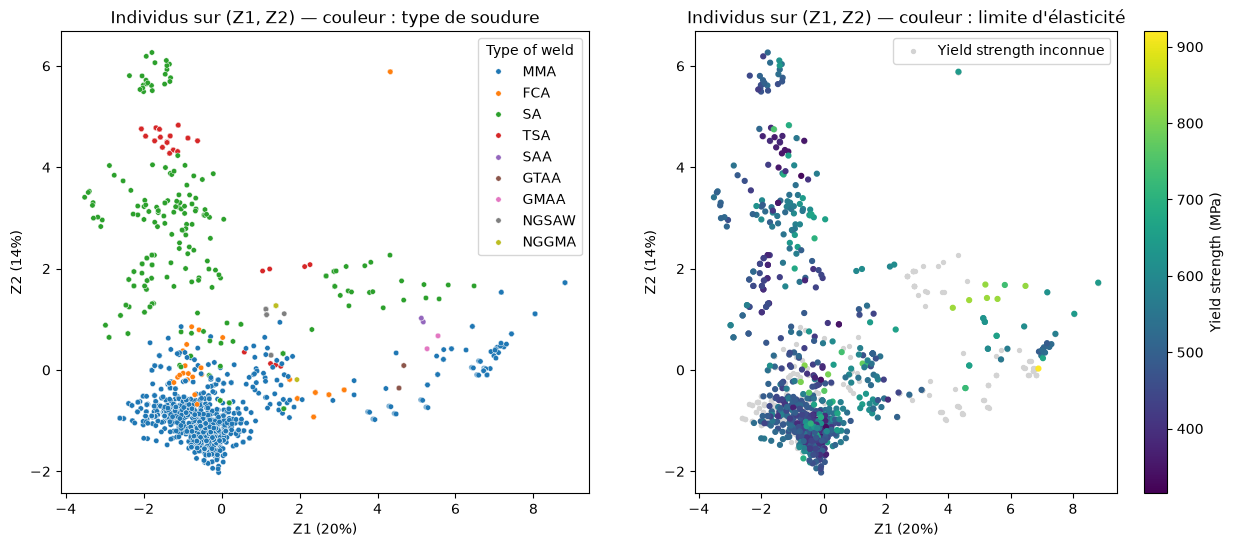

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["Type of weld"], s=15, ax=axes[0])
axes[0].set_title("Individus sur (Z1, Z2) — couleur : type de soudure")

lab = df["Yield strength"].notna()
axes[1].scatter(scores[~lab, 0], scores[~lab, 1], s=8, c="lightgrey", label="Yield strength inconnue")
sc = axes[1].scatter(scores[lab, 0], scores[lab, 1], s=12, c=df.loc[lab, "Yield strength"], cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="Yield strength (MPa)")
axes[1].legend(loc="upper right"); axes[1].set_title("Individus sur (Z1, Z2) — couleur : limite d'élasticité")
for ax in axes:
    ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
plt.show()

**Variance expliquée**
- La variance est répartie sur beaucoup d'axes : Z1 porte 20 %, Z2 14 %, soit 34 % pour le premier plan. Il faut 11 composantes pour atteindre 80 % (critère de Kaiser : 6).
- La structure n'est donc pas réductible à 2 ou 3 dimensions. Le plan (Z1, Z2) sert à l'interprétation, pas à une réduction drastique avant modélisation.

**Cercle des corrélations**
- **Z1 = axe « alliage et revenu »** : `Cr`, `V`, `Mo`, `Nb`, `N` et `PWHT temperature` y contribuent positivement (r ≈ 0,6 à 0,9), ce qui confirme le bloc d'alliage associé aux revenus chauds.
- **Z2 = axe « procédé »** : `Current`, `Heat input` et `Voltage` (r ≈ 0,8 à 0,9) dominent, avec `S`, `P` et `C` dans une moindre mesure.
- Les deux axes sont presque orthogonaux : la composition d'alliage et les paramètres de soudage sont deux sources de variabilité indépendantes.
- `Mn`, `Si` et la température d'interpasse s'opposent à l'axe d'alliage (côté négatif de Z1).

**Individus**
- **Type de soudure** : les soudures à l'arc submergé (SA, TSA) occupent le haut de Z2 (forte énergie), tandis que la majorité des soudures MMA forme un nuage dense en bas, à faible énergie. Le procédé structure donc la base.
- **Limite d'élasticité** : elle augmente vers la droite (Z1), surtout au-delà de Z1 ≈ 4, c'est-à-dire pour les aciers alliés. Le long de Z2, aucun gradient net n'apparaît.
- Les points sans limite d'élasticité connue (gris) sont répartis dans tout le plan, ce qui est encourageant pour l'approche semi-supervisée, même si le groupe de droite (aciers alliés) est moins couvert.

**Conséquences**
- La composition d'alliage (Z1) est le principal levier des cibles de résistance, le procédé (Z2) joue davantage sur les autres cibles (striction, ténacité), ce qui rejoint l'analyse de corrélation.
- Aucune réduction par ACP n'est nécessaire : on garde les variables d'origine avec des modèles robustes à la redondance ou régularisés.
- Le regroupement par procédé confirme l'intérêt d'une validation par groupes (`GroupKFold`).

---

## Enregistrement des données

In [34]:
df.to_csv(r"..\1. Données\02_intermediate" + "/welddb_processed_vf.csv", sep=";", index=False)
CORRESP.to_csv(r"..\1. Données\02_intermediate" + "/correspondance_between_names_units_vf.csv", sep=";", index=False)